In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from typing import List, Dict, Optional
import warnings
import os





In [2]:
# --- Global font settings (consistent, larger, bold titles) ---
# Matches the scheme used by liver_fibrosis_utils.apply_plot_style(), so figures
# produced directly in this notebook (e.g. the zonation-reconstruction summary
# figure below) look consistent with the ones produced by the utils functions.
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 24,
    "axes.titleweight": "bold",
    "axes.labelsize": 22,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 16,
    "legend.title_fontsize": 17,
    "figure.titlesize": 26,
    "figure.titleweight": "bold",
})


In [ ]:
adata = sc.read_h5ad("adata_healthy_diseased_merfish.h5ad")

In [ ]:
adata.obsm['spatial'] = adata.obsm['X_spatial']

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [ ]:
"""
Liver Zonation Reconstruction - Hepatocytes Only
=================================================

Runs zonation reconstruction specifically on hepatocyte populations.
Filters data by Cell_Type_final column.

Based on: Halpern et al. Nature 2017, Kalucka et al. Cell 2020
"""


# ============================================================================
# CONFIGURATION - MODIFY THIS SECTION
# ============================================================================

# Your data file
DATA_FILE = 'adata_healthy_diseased_merfish.h5ad'  # <<< CHANGE THIS

# Cell type column and hepatocyte labels
CELL_TYPE_COLUMN = 'Cell_Type_final'
HEPATOCYTE_TYPES = ['Central Hep', 'Fibrotic Hep 1', 'Fibrotic Hep 2', 'Portal Hep']

# Analysis parameters
N_LAYERS = 9
SPECIES = 'auto'  # 'auto', 'human', or 'mouse'

# ============================================================================
# GENE DEFINITIONS
# ============================================================================

HUMAN_ZONATION_MARKERS = {
    'central': ['CYP2E1', 'GLUL', 'CYP1A2', 'CYP3A4', 'CYP2A6', 'CYP2C9',
                'CYP2D6', 'GSTA1', 'GSTA2', 'GSTP1', 'ALDH1A1', 'GPX1',
                'SOD1', 'CAT', 'BLVRB'],
    'portal': ['ASS1', 'ASL', 'CPS1', 'ALB', 'APOA1', 'APOA2', 'APOB',
               'APOC3', 'PCK1', 'G6PC', 'FBP1', 'HAL', 'PAH', 'TAT', 'HPD']
}

MOUSE_LANDMARK_GENES = {
    'central': ['Akr1c6', 'Alad', 'Blvrb', 'C6', 'Car3', 'Ccdc107', 'Cml2',
                'Cyp2c68', 'Cyp2d9', 'Cyp3a11', 'Entpd5', 'Fmo1', 'Gsta3',
                'Gstm1', 'Gstm6', 'Gstt1', 'Hpd', 'Hsd17b10', 'Inmt',
                'Iqgap2', 'Mgst1', 'Nrn1', 'Pex11a', 'Pon1', 'Psmd4',
                'Slc22a1', 'Tex264'],
    'portal': ['Afm', 'Aldh1l1', 'Asl', 'Ass1', 'Atp5a1', 'Atp5g1',
               'C8a', 'C8b', 'Ces3b', 'Cyp2f2', 'Elovl2', 'Fads1',
               'Fbp1', 'Ftcd', 'Gm2a', 'Hpx', 'Hsd17b13', 'Ifitm3',
               'Igf1', 'Igfals', 'Khk', 'Mug2', 'Pygl', 'Sepp1',
               'Serpina1c', 'Serpina1e', 'Serpind1', 'Vtn']
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def detect_species(adata) -> str:
    """Detect if data is mouse or human based on gene names."""
    genes = set(list(adata.var_names)[:1000])
    mouse_pattern = sum(1 for g in genes if len(g) > 1 and g[0].isupper() and g[1].islower())
    human_pattern = sum(1 for g in genes if g.isupper())
    return 'mouse' if mouse_pattern > human_pattern else 'human' if human_pattern > mouse_pattern else 'unknown'

def get_landmark_genes(adata, species: str) -> Dict[str, List[str]]:
    """Get landmark genes based on species."""
    available_genes = set(adata.var_names)
    genes = MOUSE_LANDMARK_GENES if species == 'mouse' else HUMAN_ZONATION_MARKERS

    central = [g for g in genes['central'] if g in available_genes]
    portal = [g for g in genes['portal'] if g in available_genes]

    print(f"   Found {len(central)} central and {len(portal)} portal landmark genes")
    return {'central': central, 'portal': portal}

# ============================================================================
# MAIN RECONSTRUCTION CLASS
# ============================================================================

class LiverZonationReconstructor:
    """Reconstruct spatial zonation profiles from hepatocytes."""

    def __init__(self, adata: sc.AnnData):
        self.adata = adata.copy()
        self.landmark_genes = {'central': [], 'portal': []}
        self.cell_positions = None
        self.layer_probabilities = None

    def set_landmark_genes(self, central: List[str], portal: List[str]):
        available = set(self.adata.var_names)
        self.landmark_genes['central'] = [g for g in central if g in available]
        self.landmark_genes['portal'] = [g for g in portal if g in available]

    def compute_cell_positions(self) -> np.ndarray:
        """Compute cell positions along porto-central axis."""
        central_idx = [self.adata.var_names.get_loc(g) for g in self.landmark_genes['central']]
        portal_idx = [self.adata.var_names.get_loc(g) for g in self.landmark_genes['portal']]

        X = self.adata.X.toarray() if hasattr(self.adata.X, 'toarray') else self.adata.X
        central_expr = X[:, central_idx]
        portal_expr = X[:, portal_idx]

        # Normalize to max
        central_expr = central_expr / (central_expr.max(axis=0, keepdims=True) + 1e-10)
        portal_expr = portal_expr / (portal_expr.max(axis=0, keepdims=True) + 1e-10)

        # Calculate position
        central_sum = central_expr.sum(axis=1)
        portal_sum = portal_expr.sum(axis=1)
        mu_i = portal_sum / (portal_sum + central_sum + 1e-10)

        self.cell_positions = mu_i
        self.adata.obs['zonation_position'] = mu_i
        return mu_i

    def assign_layers(self, n_layers: int = 9) -> np.ndarray:
        """Assign cells to discrete layers."""
        if self.cell_positions is None:
            self.compute_cell_positions()

        layers = np.zeros(len(self.cell_positions), dtype=int)
        quantiles = np.linspace(0, 1, n_layers + 1)

        for i in range(n_layers):
            lower = np.quantile(self.cell_positions, quantiles[i])
            upper = np.quantile(self.cell_positions, quantiles[i + 1])
            mask = (self.cell_positions >= lower) & (self.cell_positions <= upper if i == n_layers - 1 else self.cell_positions < upper)
            layers[mask] = i + 1

        self.adata.obs['zonation_layer'] = layers
        return layers

    def compute_layer_probabilities(self, n_layers: int = 9) -> np.ndarray:
        """Compute soft layer assignments."""
        if self.cell_positions is None:
            self.compute_cell_positions()

        probs = np.zeros((len(self.cell_positions), n_layers))

        for layer in range(1, n_layers + 1):
            center = (layer - 0.5) / n_layers
            width = 0.5 / n_layers
            probs[:, layer - 1] = stats.norm.pdf(self.cell_positions, loc=center, scale=width)

        probs = probs / (probs.sum(axis=1, keepdims=True) + 1e-10)
        self.layer_probabilities = probs
        return probs

    def reconstruct_layer_expression(self, n_layers: int = 9) -> pd.DataFrame:
        """Reconstruct gene expression profiles per layer."""
        if self.layer_probabilities is None:
            self.compute_layer_probabilities(n_layers)

        X = self.adata.X.toarray() if hasattr(self.adata.X, 'toarray') else self.adata.X
        layer_expr = np.zeros((self.adata.n_vars, n_layers))

        for i in range(n_layers):
            weights = self.layer_probabilities[:, i][:, np.newaxis]
            layer_expr[:, i] = (X * weights).sum(axis=0) / (weights.sum() + 1e-10)

        return pd.DataFrame(layer_expr, index=self.adata.var_names,
                          columns=[f'Layer_{i+1}' for i in range(n_layers)])

def find_zonated_genes(layer_expr: pd.DataFrame, min_fc: float = 2.0) -> pd.DataFrame:
    """Find zonated genes."""
    layer_cols = [c for c in layer_expr.columns if c.startswith('Layer_')]
    results = []

    for gene in layer_expr.index:
        expr = layer_expr.loc[gene, layer_cols].values
        max_val, min_val = expr.max(), expr.min()
        fc = max_val / (min_val + 1e-10)
        max_layer = layer_cols[expr.argmax()]

        results.append({
            'gene': gene, 'fold_change': fc, 'mean_expr': expr.mean(),
            'max_layer': max_layer,
            'zonation_type': 'central' if int(max_layer.split('_')[1]) > 5 else 'portal'
        })

    df = pd.DataFrame(results)
    return df[df['fold_change'] >= min_fc].sort_values('fold_change', ascending=False)

# ============================================================================
# MAIN ANALYSIS
# ============================================================================

def main():
    print("="*70)
    print("LIVER ZONATION RECONSTRUCTION - HEPATOCYTES ONLY")
    print("="*70)

    # Load data
    print(f"\n1. Loading data from: {DATA_FILE}")
    adata_full = sc.read_h5ad(DATA_FILE)
    print(f"   Loaded: {adata_full.n_obs} cells Ãƒâ€” {adata_full.n_vars} genes")

    # Check cell type column
    if CELL_TYPE_COLUMN not in adata_full.obs.columns:
        print(f"\n   ERROR: Column '{CELL_TYPE_COLUMN}' not found!")
        print(f"   Available columns: {list(adata_full.obs.columns)}")
        return

    # Show cell type distribution
    print(f"\n2. Cell type distribution:")
    cell_counts = adata_full.obs[CELL_TYPE_COLUMN].value_counts()
    for ct, count in cell_counts.items():
        marker = "Ã¢Å“â€œ" if ct in HEPATOCYTE_TYPES else " "
        print(f"   {marker} {ct}: {count} cells")

    # Filter for hepatocytes
    print(f"\n3. Filtering for hepatocytes...")
    hep_mask = adata_full.obs[CELL_TYPE_COLUMN].isin(HEPATOCYTE_TYPES)
    adata_hep = adata_full[hep_mask].copy()
    print(f"   Selected {adata_hep.n_obs} hepatocytes ({adata_hep.n_obs/adata_full.n_obs*100:.1f}%)")

    print("\n   Hepatocyte subtypes:")
    for ct in HEPATOCYTE_TYPES:
        if ct in adata_hep.obs[CELL_TYPE_COLUMN].values:
            count = (adata_hep.obs[CELL_TYPE_COLUMN] == ct).sum()
            print(f"     - {ct}: {count} cells")

    # Detect species
    species = SPECIES if SPECIES != 'auto' else detect_species(adata_hep)
    print(f"\n4. Detected species: {species}")

    # Get landmark genes
    print("\n5. Setting landmark genes...")
    landmarks = get_landmark_genes(adata_hep, species)

    # Initialize reconstructor
    print("\n6. Running zonation reconstruction on hepatocytes...")
    reconstructor = LiverZonationReconstructor(adata_hep)
    reconstructor.set_landmark_genes(landmarks['central'], landmarks['portal'])

    # Run analysis
    print("   - Computing cell positions...")
    positions = reconstructor.compute_cell_positions()

    print("   - Assigning layers...")
    layers = reconstructor.assign_layers(N_LAYERS)

    print("   - Computing probabilities...")
    probs = reconstructor.compute_layer_probabilities(N_LAYERS)

    print("   - Reconstructing expression profiles...")
    layer_expr = reconstructor.reconstruct_layer_expression(N_LAYERS)

    print("   - Finding zonated genes...")
    zonated = find_zonated_genes(layer_expr)

    # Transfer results back to full dataset
    print("\n7. Transferring results to full dataset...")
    adata_full.obs['zonation_position'] = np.nan
    adata_full.obs['zonation_layer'] = 0

    # Use reconstructor.adata which has the results, not adata_hep
    adata_full.obs.loc[hep_mask, 'zonation_position'] = reconstructor.adata.obs['zonation_position'].values
    adata_full.obs.loc[hep_mask, 'zonation_layer'] = reconstructor.adata.obs['zonation_layer'].values

    # Also update adata_hep for the hepatocyte-only output
    adata_hep.obs['zonation_position'] = reconstructor.adata.obs['zonation_position'].values
    adata_hep.obs['zonation_layer'] = reconstructor.adata.obs['zonation_layer'].values

    # Results
    print("\n" + "="*70)
    print("RESULTS")
    print("="*70)
    print(f"\nHepatocytes analyzed: {adata_hep.n_obs}")
    print(f"Position range: {positions.min():.3f} to {positions.max():.3f}")
    print(f"Mean position: {positions.mean():.3f}")

    print(f"\nZonated genes found: {len(zonated)}")
    print(f"  Portal-biased: {(zonated['zonation_type']=='portal').sum()}")
    print(f"  Central-biased: {(zonated['zonation_type']=='central').sum()}")

    print("\nTop 10 most zonated genes:")
    print(zonated.head(10)[['gene', 'fold_change', 'zonation_type']].to_string(index=False))

    print("\nPosition by cell type:")
    for ct in HEPATOCYTE_TYPES:
        if ct in reconstructor.adata.obs[CELL_TYPE_COLUMN].values:
            ct_mask = reconstructor.adata.obs[CELL_TYPE_COLUMN] == ct
            mean_pos = reconstructor.adata.obs.loc[ct_mask, 'zonation_position'].mean()
            print(f"  {ct:20s}: {mean_pos:.3f}")

    # Save results
    print("\n8. Saving results...")
    layer_expr.to_csv('zonation_layer_expression_hepatocytes.csv')
    zonated.to_csv('zonated_genes_hepatocytes.csv', index=False)
    adata_full.write_h5ad('merfish_with_zonation_full.h5ad')
    adata_hep.write_h5ad('merfish_hepatocytes_zonation.h5ad')

    print("   Ã¢Å“â€œ zonation_layer_expression_hepatocytes.csv")
    print("   Ã¢Å“â€œ zonated_genes_hepatocytes.csv")
    print("   Ã¢Å“â€œ merfish_with_zonation_full.h5ad (all cells, hepatocytes have zonation)")
    print("   Ã¢Å“â€œ merfish_hepatocytes_zonation.h5ad (hepatocytes only)")

    # Visualization
    print("\n9. Creating visualizations...")
    fig = plt.figure(figsize=(16, 12))
    gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

    # Get positions for plotting
    positions = reconstructor.adata.obs['zonation_position'].values
    layers = reconstructor.adata.obs['zonation_layer'].values

    # Position histogram
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.hist(positions, bins=50, edgecolor='black', alpha=0.7)
    ax1.set_xlabel('Position (0=Portal, 1=Central)')
    ax1.set_ylabel('Hepatocytes')
    ax1.set_title('Zonation Position Distribution')
    ax1.grid(True, alpha=0.3)

    # Layer counts
    ax2 = fig.add_subplot(gs[0, 1])
    layer_counts = pd.Series(layers).value_counts().sort_index()
    ax2.bar(layer_counts.index, layer_counts.values, edgecolor='black', alpha=0.7)
    ax2.set_xlabel('Layer')
    ax2.set_ylabel('Hepatocytes')
    ax2.set_title('Cells per Layer')
    ax2.grid(True, alpha=0.3, axis='y')

    # Position by cell type
    ax3 = fig.add_subplot(gs[0, 2])
    ct_positions = []
    ct_labels = []
    for ct in HEPATOCYTE_TYPES:
        if ct in reconstructor.adata.obs[CELL_TYPE_COLUMN].values:
            ct_mask = reconstructor.adata.obs[CELL_TYPE_COLUMN] == ct
            ct_positions.append(positions[ct_mask])
            ct_labels.append(ct.replace(' Hep', '').replace('Hep ', ''))

    ax3.violinplot(ct_positions, showmeans=True)
    ax3.set_xticks(range(1, len(ct_labels) + 1))
    ax3.set_xticklabels(ct_labels, rotation=45, ha='right')
    ax3.set_ylabel('Position')
    ax3.set_title('Position by Cell Type')
    ax3.grid(True, alpha=0.3, axis='y')

    # Top zonated genes
    ax4 = fig.add_subplot(gs[1, :])
    for gene in zonated.head(8)['gene']:
        if gene in layer_expr.index:
            y = layer_expr.loc[gene, [f'Layer_{i+1}' for i in range(N_LAYERS)]].values
            ax4.plot(range(1, N_LAYERS+1), y, marker='o', label=gene, linewidth=2)
    ax4.set_xlabel('Layer (1=Portal Ã¢â€ â€™ Central)')
    ax4.set_ylabel('Expression')
    ax4.set_title('Top Zonated Genes')
    ax4.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    ax4.grid(True, alpha=0.3)

    # Landmark genes - Central
    ax5 = fig.add_subplot(gs[2, 0])
    for gene in landmarks['central'][:5]:
        if gene in layer_expr.index:
            y = layer_expr.loc[gene, [f'Layer_{i+1}' for i in range(N_LAYERS)]].values
            ax5.plot(range(1, N_LAYERS+1), y, marker='o', label=gene, linewidth=2)
    ax5.set_xlabel('Layer')
    ax5.set_ylabel('Expression')
    ax5.set_title('Central Landmark Genes')
    ax5.legend(fontsize=12)
    ax5.grid(True, alpha=0.3)

    # Landmark genes - Portal
    ax6 = fig.add_subplot(gs[2, 1])
    for gene in landmarks['portal'][:5]:
        if gene in layer_expr.index:
            y = layer_expr.loc[gene, [f'Layer_{i+1}' for i in range(N_LAYERS)]].values
            ax6.plot(range(1, N_LAYERS+1), y, marker='o', label=gene, linewidth=2)
    ax6.set_xlabel('Layer')
    ax6.set_ylabel('Expression')
    ax6.set_title('Portal Landmark Genes')
    ax6.legend(fontsize=12)
    ax6.grid(True, alpha=0.3)

    # Zonation type distribution
    ax7 = fig.add_subplot(gs[2, 2])
    type_counts = zonated['zonation_type'].value_counts()
    colors = ['#d62728', '#1f77b4']
    ax7.bar(type_counts.index, type_counts.values, color=colors, edgecolor='black', alpha=0.7)
    ax7.set_ylabel('Number of Genes')
    ax7.set_title('Zonation Type Distribution')
    ax7.grid(True, alpha=0.3, axis='y')

    plt.suptitle('Liver Zonation Analysis - Hepatocytes Only', fontsize=20, fontweight='bold')
    plt.savefig('zonation_hepatocytes_summary.png', dpi=300, bbox_inches='tight')
    print("   Ã¢Å“â€œ zonation_hepatocytes_summary.png")

    print("\n" + "="*70)
    print("ANALYSIS COMPLETE!")
    print("="*70)
    print("\nNote: Only hepatocytes have zonation values.")
    print("      Non-hepatocytes have NaN for position and 0 for layer.")
    return adata_hep
adata_hep = main()
fibrosis_directory = "../fibrosis_figures_pearson_XY"
distance_matrix_encoding = False
os.makedirs(fibrosis_directory, exist_ok=True)
sc.settings.figdir = fibrosis_directory
adata_path = os.path.join(fibrosis_directory, "original_full_adata.h5ad")
adata_hep.obsm['spatial'] = adata_hep.obsm['X_spatial']

adata_hep.write(adata_path)


Start from here if data is already preprocessed and stored


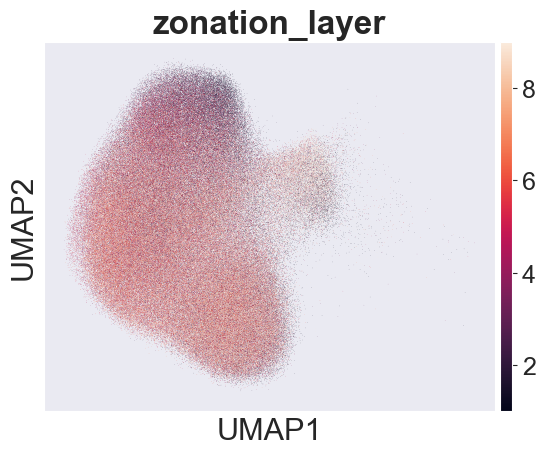

In [3]:
distance_matrix_encoding = False
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from typing import List, Dict, Optional
import warnings
import os
def initialize_settings(fibrosis_directory):
    distance_matrix_encoding = False
    sc.settings.figdir = fibrosis_directory
    adata_path = os.path.join(fibrosis_directory, "original_full_adata.h5ad")

    adata_hep = sc.read_h5ad(adata_path)

    sc.pl.umap(adata_hep, color='zonation_layer')
    adata_hep.obsm['spatial'] = adata_hep.obsm['X_spatial']
    return adata_hep
fibrosis_directory = "../fibrosis_figures_pearson_XY"
adata_hep = initialize_settings(fibrosis_directory)
import importlib

In [ ]:
fibrosis_directory = "../fibrosis_figures_pearson_XY"


Healthy samples graph score and cell level score

In [ ]:
import crisp
import importlib
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import *

metric_ = "knn"
embedding_key_ = "X"

adata_healthy_obs = adata_hep[adata_hep.obs["condition"] == "healthy"].copy()
healthy_samples = adata_healthy_obs.obs["sample_id"].unique()

sc.settings.set_figure_params(facecolor="white", fontsize=22, dpi=100)

for sid in healthy_samples:
    print(f"Processing sample: {sid}")
    subdir = os.path.join(fibrosis_directory, f"sample_{sid}")
    os.makedirs(subdir, exist_ok=True)
    sc.settings.figdir = subdir

    adata_tmp = adata_healthy_obs[adata_healthy_obs.obs["sample_id"] == sid].copy()

    if distance_matrix_encoding:
        spatial_key = crisp.encode_spatial(adata_tmp)
    else:
        spatial_key = "spatial"

    crisp.encode_obs(adata_tmp, "zonation_position")

    global_score = crisp.compute_projection_similarity(
        adata_tmp,
        signal_A="zonation_position",
        signal_B=spatial_key,
        embedding_key="X",
        metric_A="knn", metric_B="knn",
        device="cuda",
        store_projections=True,
    )

    # adata_tmp.uns["proj_mean_cell_pearson"] = global_score
    adata_path = os.path.join(subdir, "adata.h5ad")
    adata_tmp.write(adata_path)
    print(f"Sample {sid}: global_score = {adata_tmp.uns['proj_mean_cell_pearson']:.4f}")


../fibrosis_figures_pearson_XY
        sample_id condition   cell  density    area            x            y  \
4-0         AM048   healthy      5   1.4880  428.90 -1438.513878 -2973.294613   
10-0        AM048   healthy     11   1.1850  227.90 -1423.520570 -2962.354052   
14-0        AM048   healthy     15   0.9365  305.40 -1419.042927 -2952.413171   
15-0        AM048   healthy     16   0.5751  422.50 -1429.717556 -2937.231354   
16-0        AM048   healthy     17   0.9763  198.70 -1445.415536 -2914.405098   
...           ...       ...    ...      ...     ...          ...          ...   
64223-0     AM048   healthy  64224   0.9734   15.41   345.298700 -2015.625533   
64251-0     AM048   healthy  64252   1.2650   14.23 -1335.643389  -900.835211   
64559-0     AM048   healthy  64560   0.8019   21.20  -780.769341  -824.340512   
64587-0     AM048   healthy  64588   1.0620   25.43 -1403.575259 -1574.688222   
64836-0     AM048   healthy  64837   0.7752   19.35  -168.664187   144.532620 

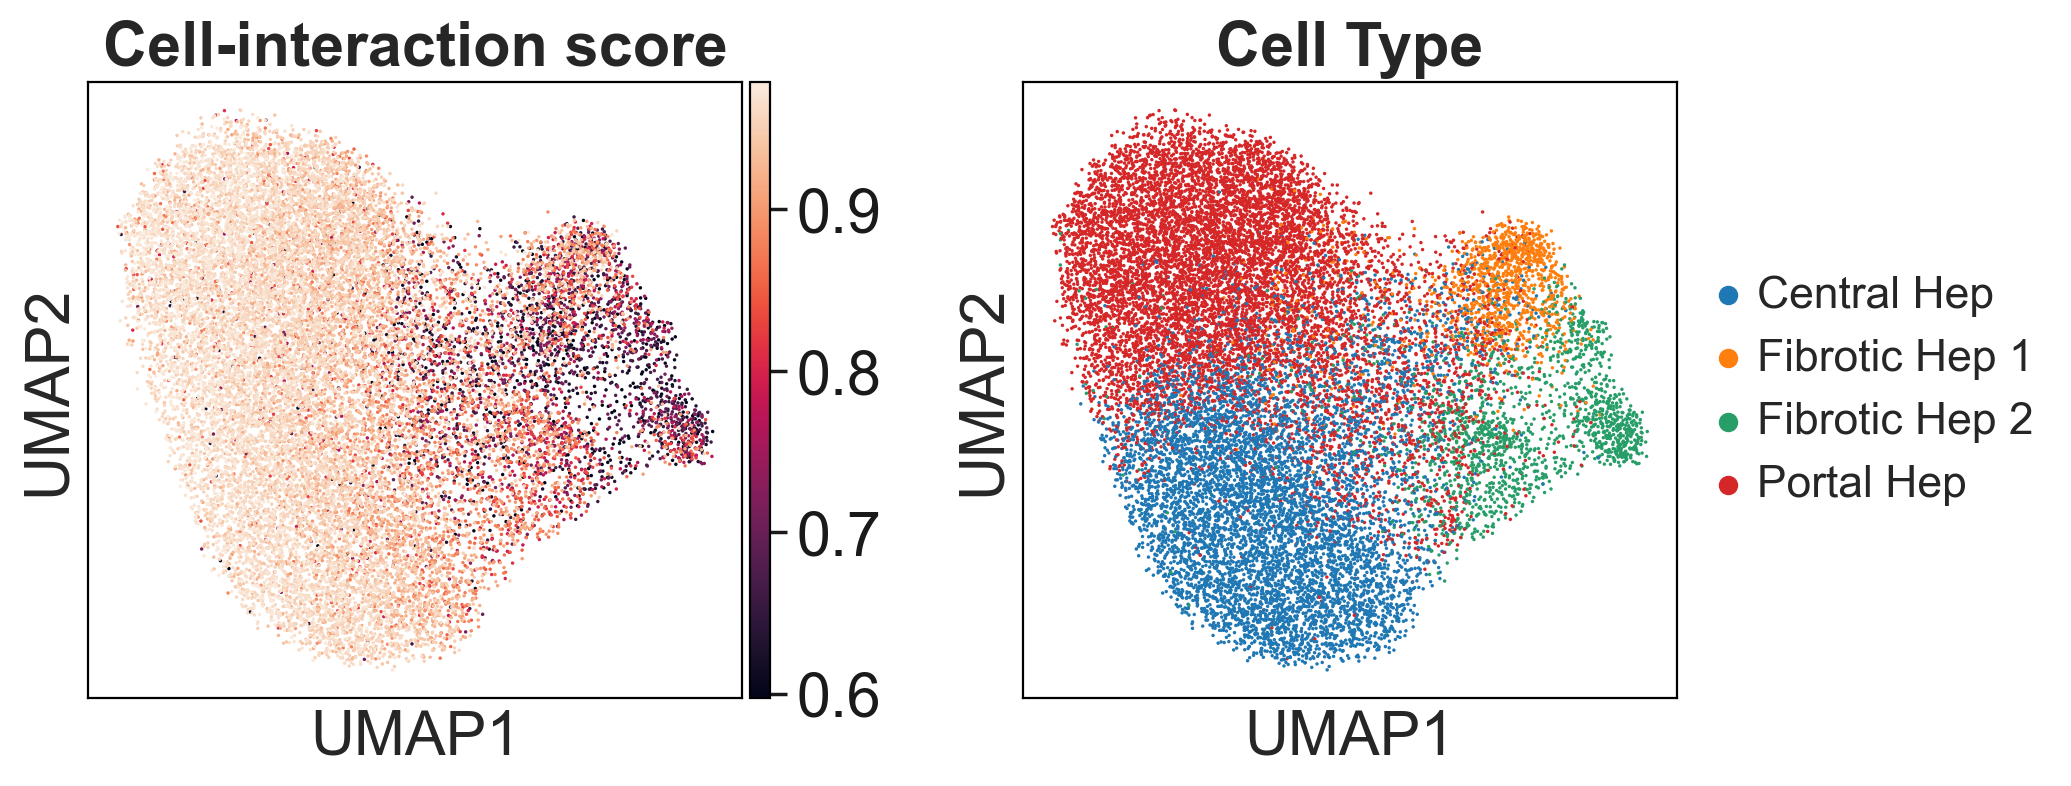

../fibrosis_figures_pearson_XY
        sample_id condition   cell  density    area            x            y  \
1-1         AM061   healthy      2   0.3346  107.60  1404.963278 -2215.950222   
2-1         AM061   healthy      3   0.4898  475.70  1414.067996 -2196.649425   
9-1         AM061   healthy     10   0.4933  141.90  1419.059357 -2163.651271   
11-1        AM061   healthy     12   0.5447  820.60  1462.920740 -2207.738226   
13-1        AM061   healthy     14   0.4237  727.00  1446.896143 -2181.922539   
...           ...       ...    ...      ...     ...          ...          ...   
48003-1     AM061   healthy  48004   1.3090   12.99  4447.595882 -1892.187647   
48213-1     AM061   healthy  48214   1.2410   14.50  6173.846444 -1552.472222   
48262-1     AM061   healthy  48263   0.8677   18.44  2623.598500 -1608.903313   
48424-1     AM061   healthy  48425   0.5374   68.85  1453.742432  -836.536711   
48437-1     AM061   healthy  48438   0.3512   51.26  6504.189778 -1140.998833 

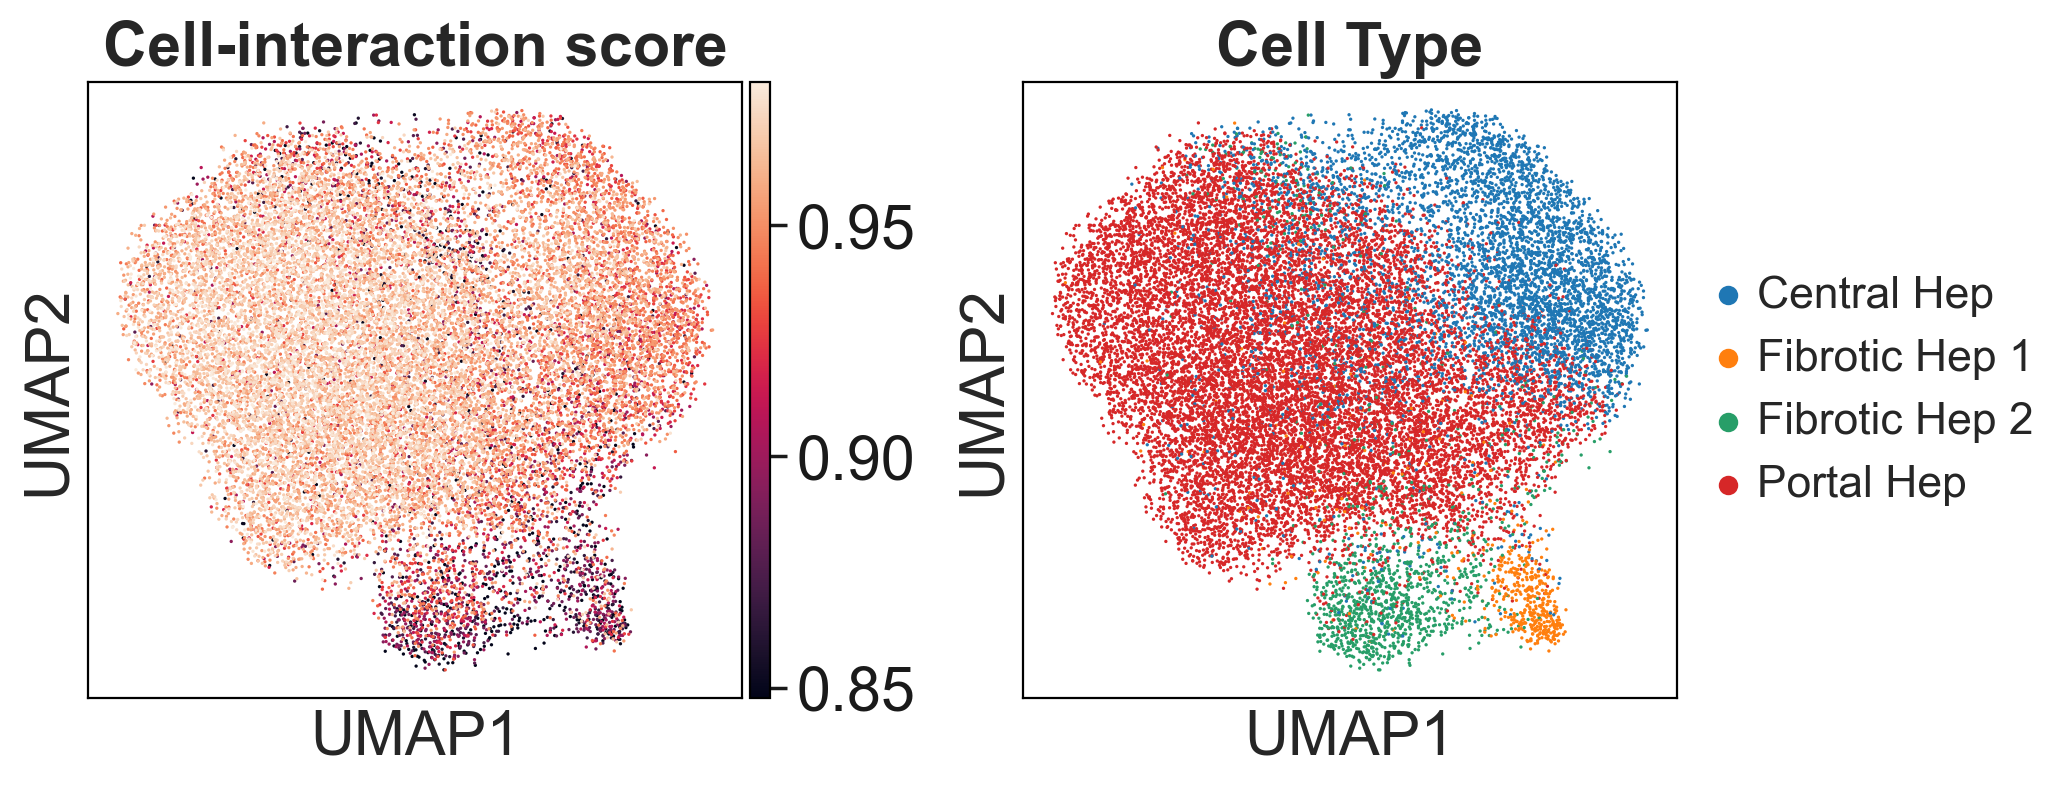

../fibrosis_figures_pearson_XY
        sample_id condition   cell  density     area            x  \
0-2         AM042   healthy      1   1.7470    9.158  -263.946875   
18-2        AM042   healthy     19   1.4770   11.510  -110.589159   
19-2        AM042   healthy     20   0.9371   25.610  -226.184425   
27-2        AM042   healthy     28   1.4760   14.230  -264.493843   
40-2        AM042   healthy     41   0.5420  393.000    -7.129391   
...           ...       ...    ...      ...      ...          ...   
53683-2     AM042   healthy  53684   0.7532   33.190   677.728084   
53721-2     AM042   healthy  53722   0.4761   44.110   917.198538   
54269-2     AM042   healthy  54270   0.7444   20.150  1907.512133   
54675-2     AM042   healthy  54676   0.5882   49.300   862.599417   
54920-2     AM042   healthy  54921   0.8436   17.780  -239.782720   

                   y batch  n_counts  log_counts  ...  \
0-2     -2389.932500     2      16.0    2.772589  ...   
18-2    -2508.164118     2

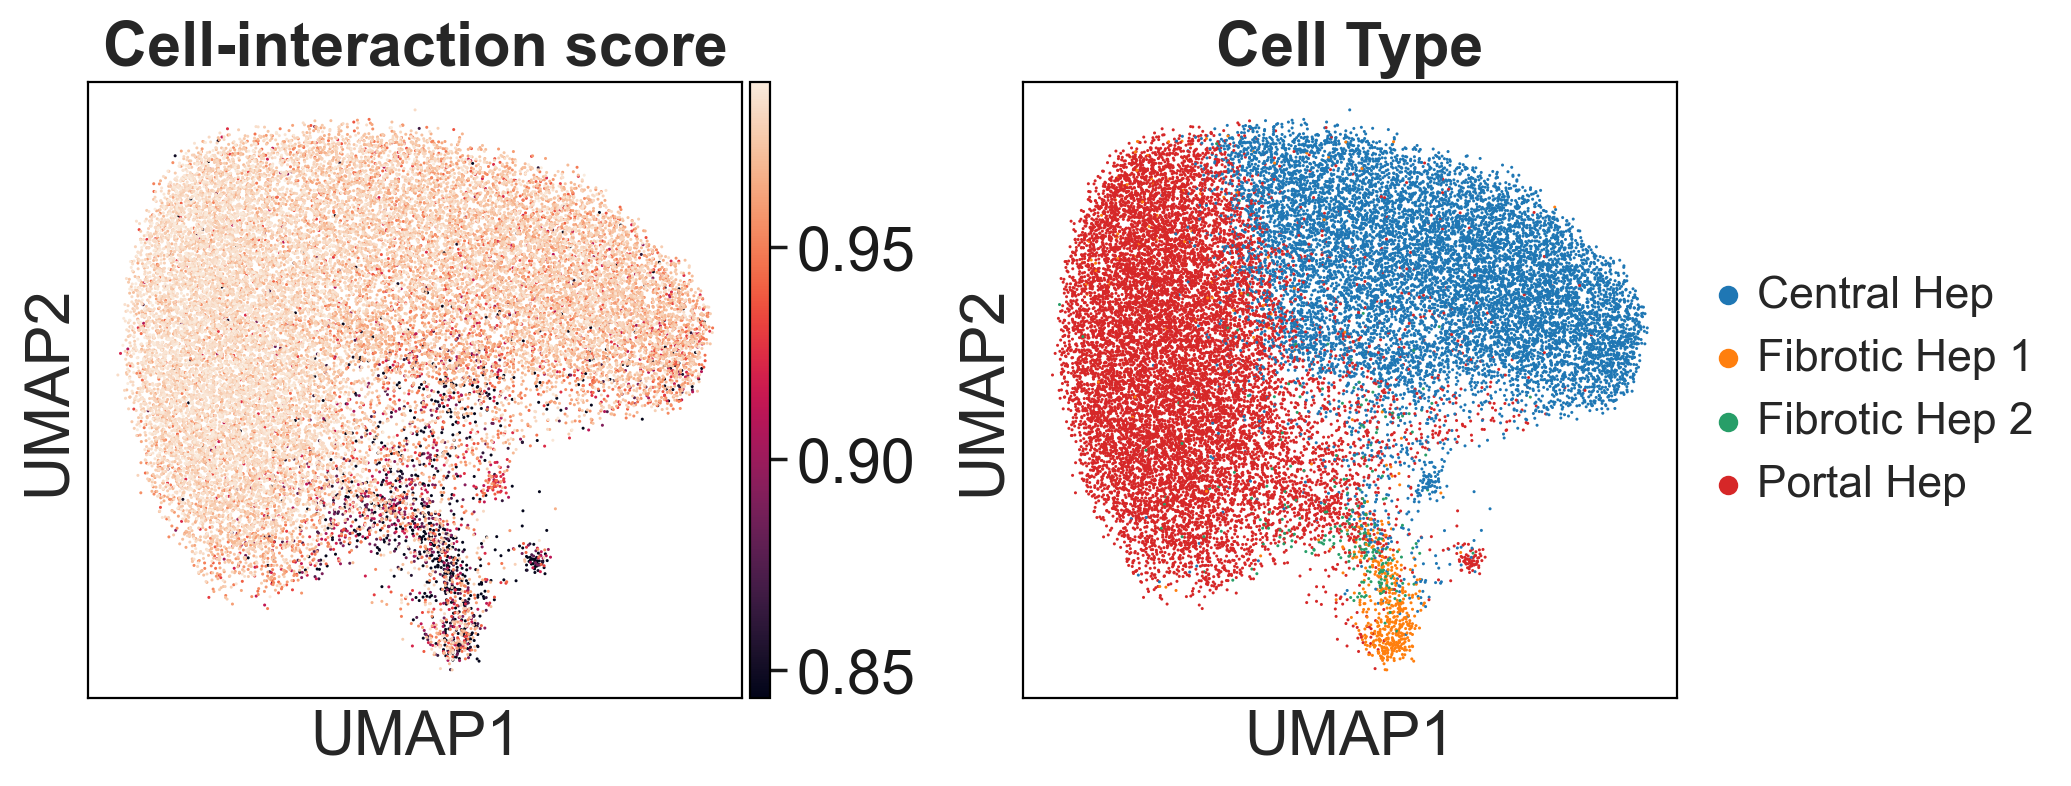

In [18]:

import liver_fibrosis_utils

importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_cell_type_distribution_by_score_bins
adata_healthy_obs = adata_hep[adata_hep.obs["condition"] == "healthy"].copy()
healthy_samples = adata_healthy_obs.obs['sample_id'].unique()

for sid in healthy_samples:
    print (fibrosis_directory)
    subdir = os.path.join(fibrosis_directory, f"sample_{sid}")
    adata_path = os.path.join(subdir, "adata.h5ad")

    # Skip if file does not exist (robust version)
    if not os.path.exists(adata_path):
        print(f"Warning: {adata_path} not found. Skipping.")
        continue

    # Load saved AnnData
    adata_tmp = sc.read_h5ad(adata_path)
    sc.settings.figdir = subdir

    plot_cell_type_distribution_by_score_bins(
        adata_tmp,
        cell_score_types=["proj_pearson_cell"],
        n_bins=10,
        remove_outliers=False
    )

In [ ]:
distance_matrix_encoding = False

In [ ]:
import crisp
import importlib
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import *

adata_diseased_obs = adata_hep[adata_hep.obs["condition"] == "diseased"].copy()
diseased_samples = adata_diseased_obs.obs["sample_id"].unique()
sc.settings.figdir = fibrosis_directory

for sid in diseased_samples:
    print(f"Processing sample: {sid}")
    subdir = os.path.join(fibrosis_directory, f"sample_{sid}")
    os.makedirs(subdir, exist_ok=True)
    sc.settings.figdir = subdir

    adata_tmp = adata_diseased_obs[adata_diseased_obs.obs["sample_id"] == sid].copy()

    if distance_matrix_encoding:
        spatial_key = crisp.encode_spatial(adata_tmp)
    else:
        spatial_key = "spatial"

    crisp.encode_obs(adata_tmp, "zonation_position")

    global_score = crisp.compute_projection_similarity(
        adata_tmp,
        signal_A="zonation_position",
        signal_B=spatial_key,
        n_neighbors=15,
        embedding_key="X",
        metric_A="knn", metric_B="knn",
        device="cuda",
        store_projections=True,
    )

    # adata_tmp.uns["proj_sim_global"] = global_score
    adata_path = os.path.join(subdir, "adata.h5ad")
    adata_tmp.write(adata_path)
    print(f"Sample {sid}: global_score = {adata_tmp.uns['proj_mean_cell_pearson']:.4f}")


Results

In [ ]:
sc.settings.figdir = fibrosis_directory
import liver_fibrosis_utils

importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_cell_type_distribution_by_score_bins

for sample_folder in os.listdir(fibrosis_directory):
    print(f"Plotting sample: {sample_folder}")
    subdir = os.path.join(fibrosis_directory, sample_folder)
    adata_path = os.path.join(subdir, "adata.h5ad")

    # Skip if file does not exist (robust version)
    if not os.path.exists(adata_path):
        print(f"Warning: {adata_path} not found. Skipping.")
        continue

    # Load saved AnnData
    adata_tmp = sc.read_h5ad(adata_path)

    sc.settings.figdir = subdir

    plot_cell_type_distribution_by_score_bins(
        adata_tmp,
        cell_score_types=["proj_pearson_cell"],
        n_bins=10,
        remove_outliers=False
    )


In [ ]:
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)
fibrosis_directory = "../fibrosis_figures_pearson_XY"

from liver_fibrosis_utils import plot_umap
sc.settings.figdir = fibrosis_directory
# plot_umap(["zonation_position", "x", "y"])

In [ ]:
# fibrosis_directory = "../fibrosis_figures_distance_m_encode"
sc.settings.figdir = fibrosis_directory
adata_diseased_obs = adata_hep[adata_hep.obs["condition"] == "diseased"]
diseased_samples = adata_diseased_obs.obs['sample_id'].unique()
adata_healthy_obs = adata_hep[adata_hep.obs["condition"] == "healthy"].copy()
healthy_samples = adata_healthy_obs.obs['sample_id'].unique()
print(healthy_samples)
print(diseased_samples)

In [ ]:
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)

from liver_fibrosis_utils import plot_global_scores
plot_global_scores(healthy_samples, diseased_samples,"proj_mean_cell_pearson")



In [ ]:
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)

from liver_fibrosis_utils import plot_score_vs_fibrotic_fraction
plot_score_vs_fibrotic_fraction(healthy_samples, diseased_samples, "proj_mean_cell_pearson")


In [11]:
import liver_fibrosis_utils

importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_cell_score_box_plots
sc.settings.figdir = fibrosis_directory
plot_cell_score_box_plots("proj_pearson_cell")

Plotting sample: AM031, ratio: nan
  [metrics] AUROC=0.635  Cliff_delta=0.271  MW_p=0.0e+00  tau(fib median)=0.781  healthy<tau=31.5%
  [medians/IQR] healthy: median=0.802 IQR=[0.772, 0.829]  |  fibrotic: median=0.781 IQR=[0.748, 0.809]
num of fibrotic cells: 11869
num of healthy cells: 34794
Plotting sample: AM062, ratio: nan
  [metrics] AUROC=0.538  Cliff_delta=0.077  MW_p=3.2e-42  tau(fib median)=0.803  healthy<tau=44.5%
  [medians/IQR] healthy: median=0.809 IQR=[0.776, 0.834]  |  fibrotic: median=0.803 IQR=[0.768, 0.830]
num of fibrotic cells: 17024
num of healthy cells: 26647
Plotting sample: AM061, ratio: nan
  [metrics] AUROC=0.826  Cliff_delta=0.651  MW_p=0.0e+00  tau(fib median)=0.905  healthy<tau=7.3%
  [medians/IQR] healthy: median=0.959 IQR=[0.943, 0.969]  |  fibrotic: median=0.905 IQR=[0.872, 0.940]
num of fibrotic cells: 1780
num of healthy cells: 19140
Plotting sample: AM048, ratio: nan
  [metrics] AUROC=0.845  Cliff_delta=0.691  MW_p=0.0e+00  tau(fib median)=0.783  heal

In [ ]:
import liver_fibrosis_utils

importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_label_vs_spatial
sc.settings.figdir = fibrosis_directory
plot_label_vs_spatial("zonation_position", show_score=False)

In [ ]:
import importlib
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_label_vs_spatial
sc.settings.figdir = fibrosis_directory

plot_label_vs_spatial("proj_pearson_cell",show_score=False)

In [ ]:
import importlib
import liver_fibrosis_utils

importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import print_top_genes_by_score
importlib.reload(liver_fibrosis_utils)
sc.settings.figdir = fibrosis_directory
print_top_genes_by_score(gene_score_key="proj_pearson_gene_contrib", n_top=10)


Sample AM031 [healthy cells only]: Spearman(FC, gene-score) = -0.574 (p=4.0e-29)  |  Pearson = -0.542 (p=1.2e-25)


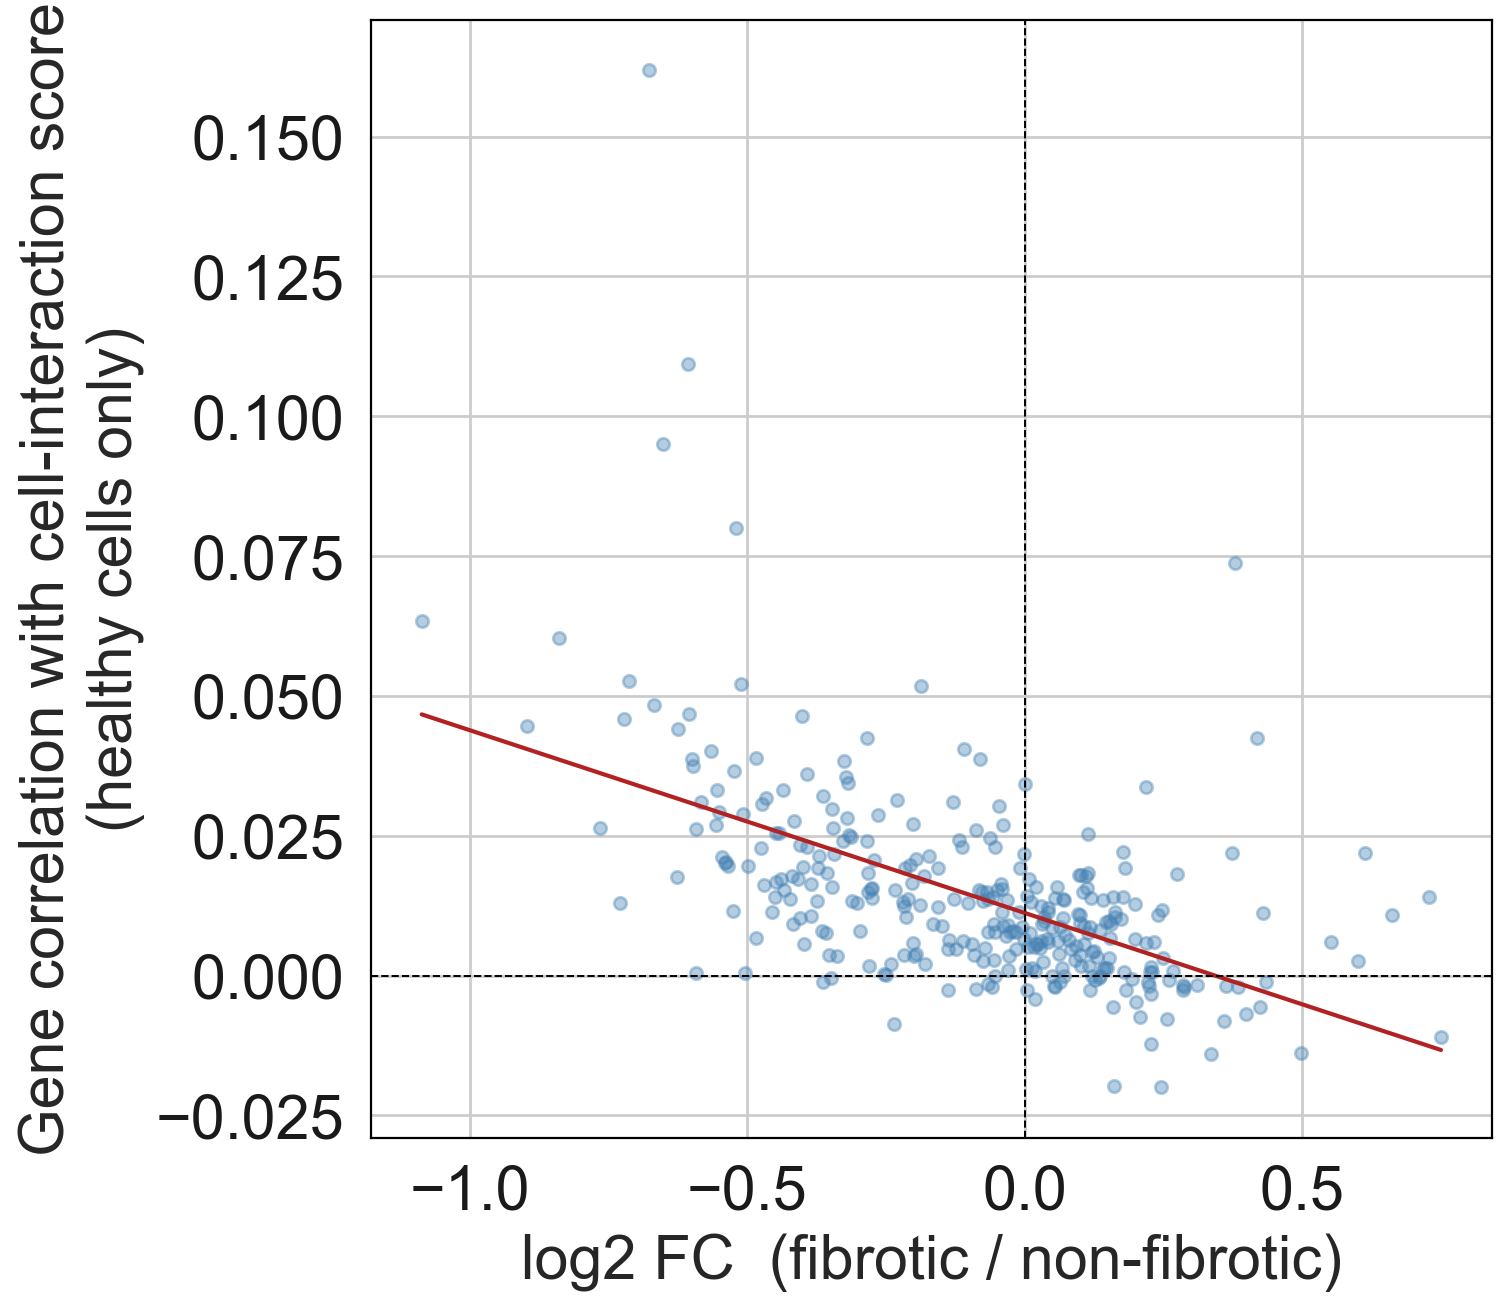


Sample AM031 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
CYP2E1        0.161846              -0.677558       0.109660
ADH1B         0.063329              -1.087332       0.068860
CYP1A2        0.109402              -0.606976       0.066404
HPD           0.094960              -0.652106       0.061924
EPHX1         0.060383              -0.839253       0.050677
FBP1          0.079948              -0.521126       0.041663
CD74          0.044663              -0.896683       0.040048
AHSG          0.052732              -0.713672       0.037633
FGA           0.045890              -0.722632       0.033161
CYP2A6        0.048374              -0.668684       0.032347
HMGCS2        0.046723              -0.604674       0.028252
CPS1          0.073748               0.379163       0.027962
CTSB          0.044036              -0.624263       0.027490
ALDH1A1       0.

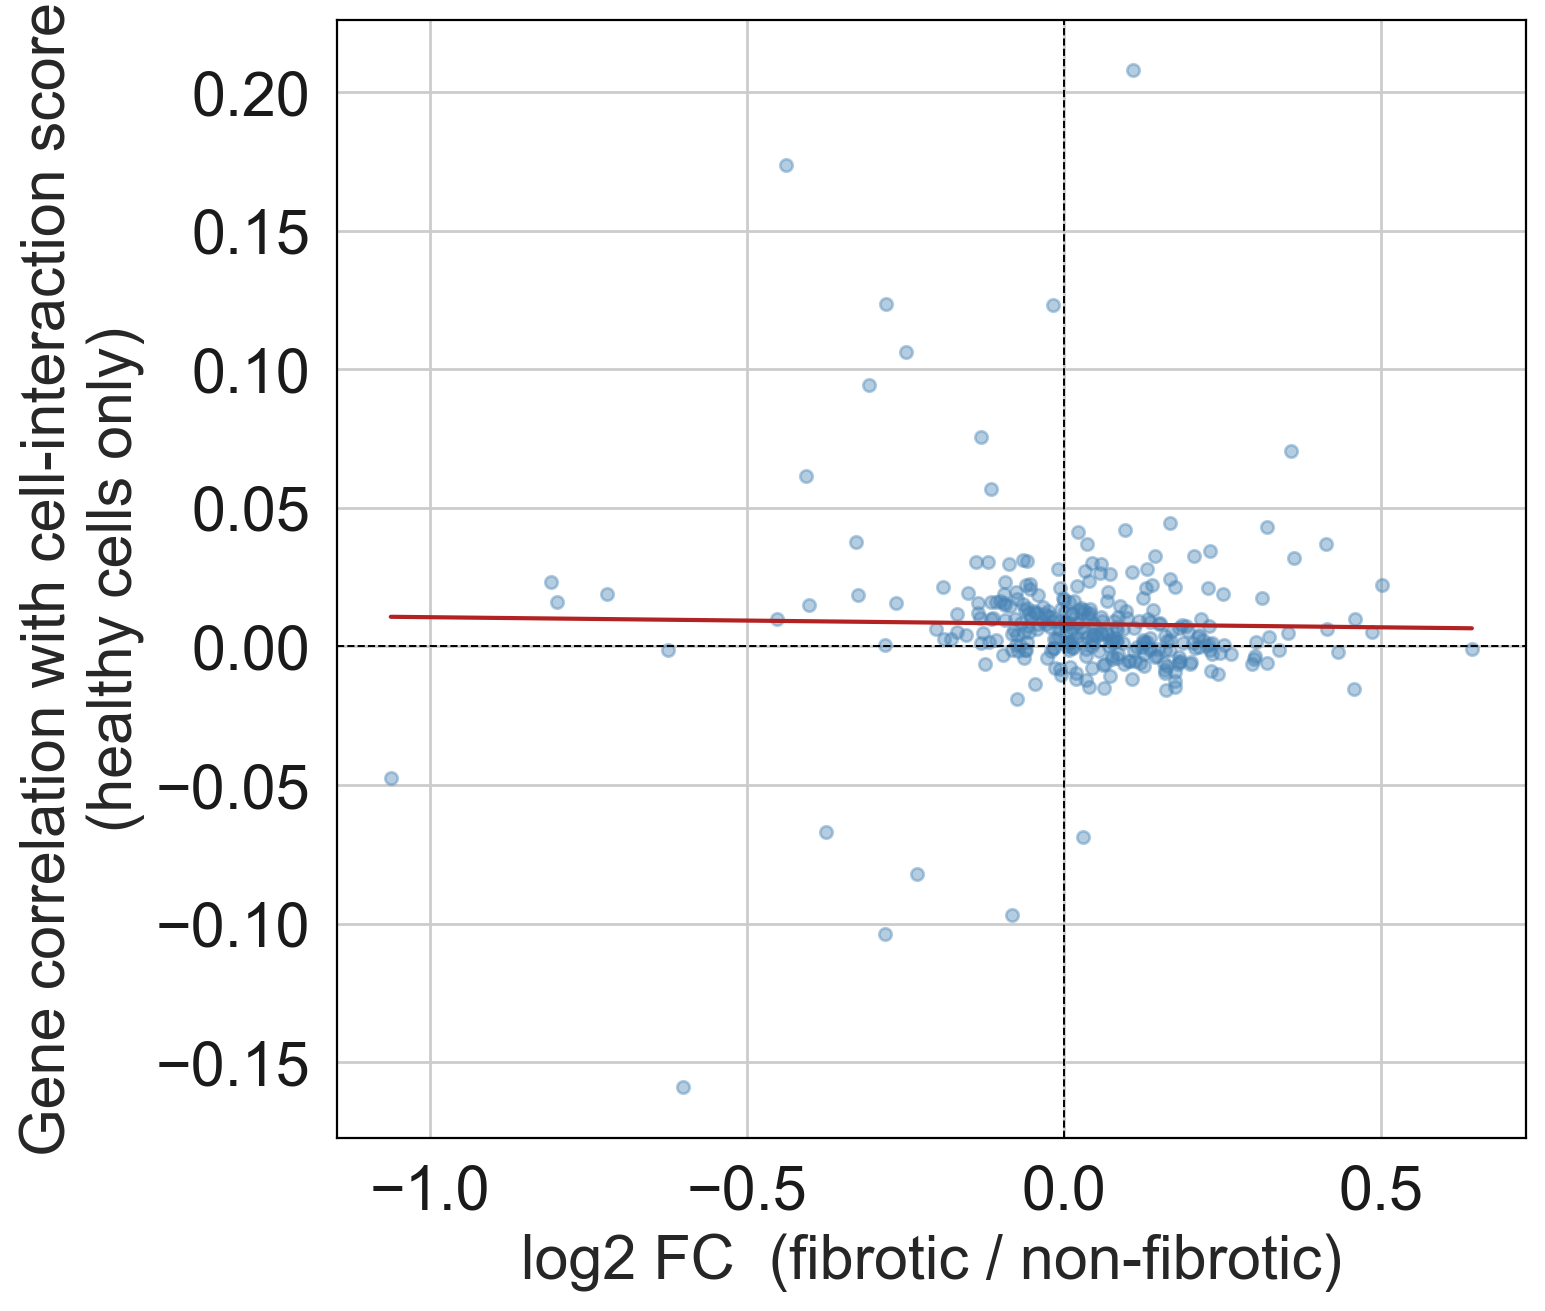


Sample AM062 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
CYP2E1       -0.159023              -0.601500   9.565232e-02
ASS1          0.173711              -0.439202   7.629417e-02
ADH1B        -0.047481              -1.062390   5.044347e-02
ALDOB         0.123423              -0.280896   3.466898e-02
ALDH1A1      -0.103903              -0.283182   2.942347e-02
FBP1          0.094471              -0.308282   2.912376e-02
SDS           0.106322              -0.249197   2.649519e-02
CYP2B6        0.070563               0.357744   2.524342e-02
CYP2A6       -0.066998              -0.375357   2.514800e-02
HPD           0.061343              -0.406848   2.495745e-02
CPS1          0.207881               0.109370   2.273592e-02
CYP3A4       -0.082015              -0.231935   1.902226e-02
FGA           0.023147              -0.810088   1.875072e-02
MEIS2         0.

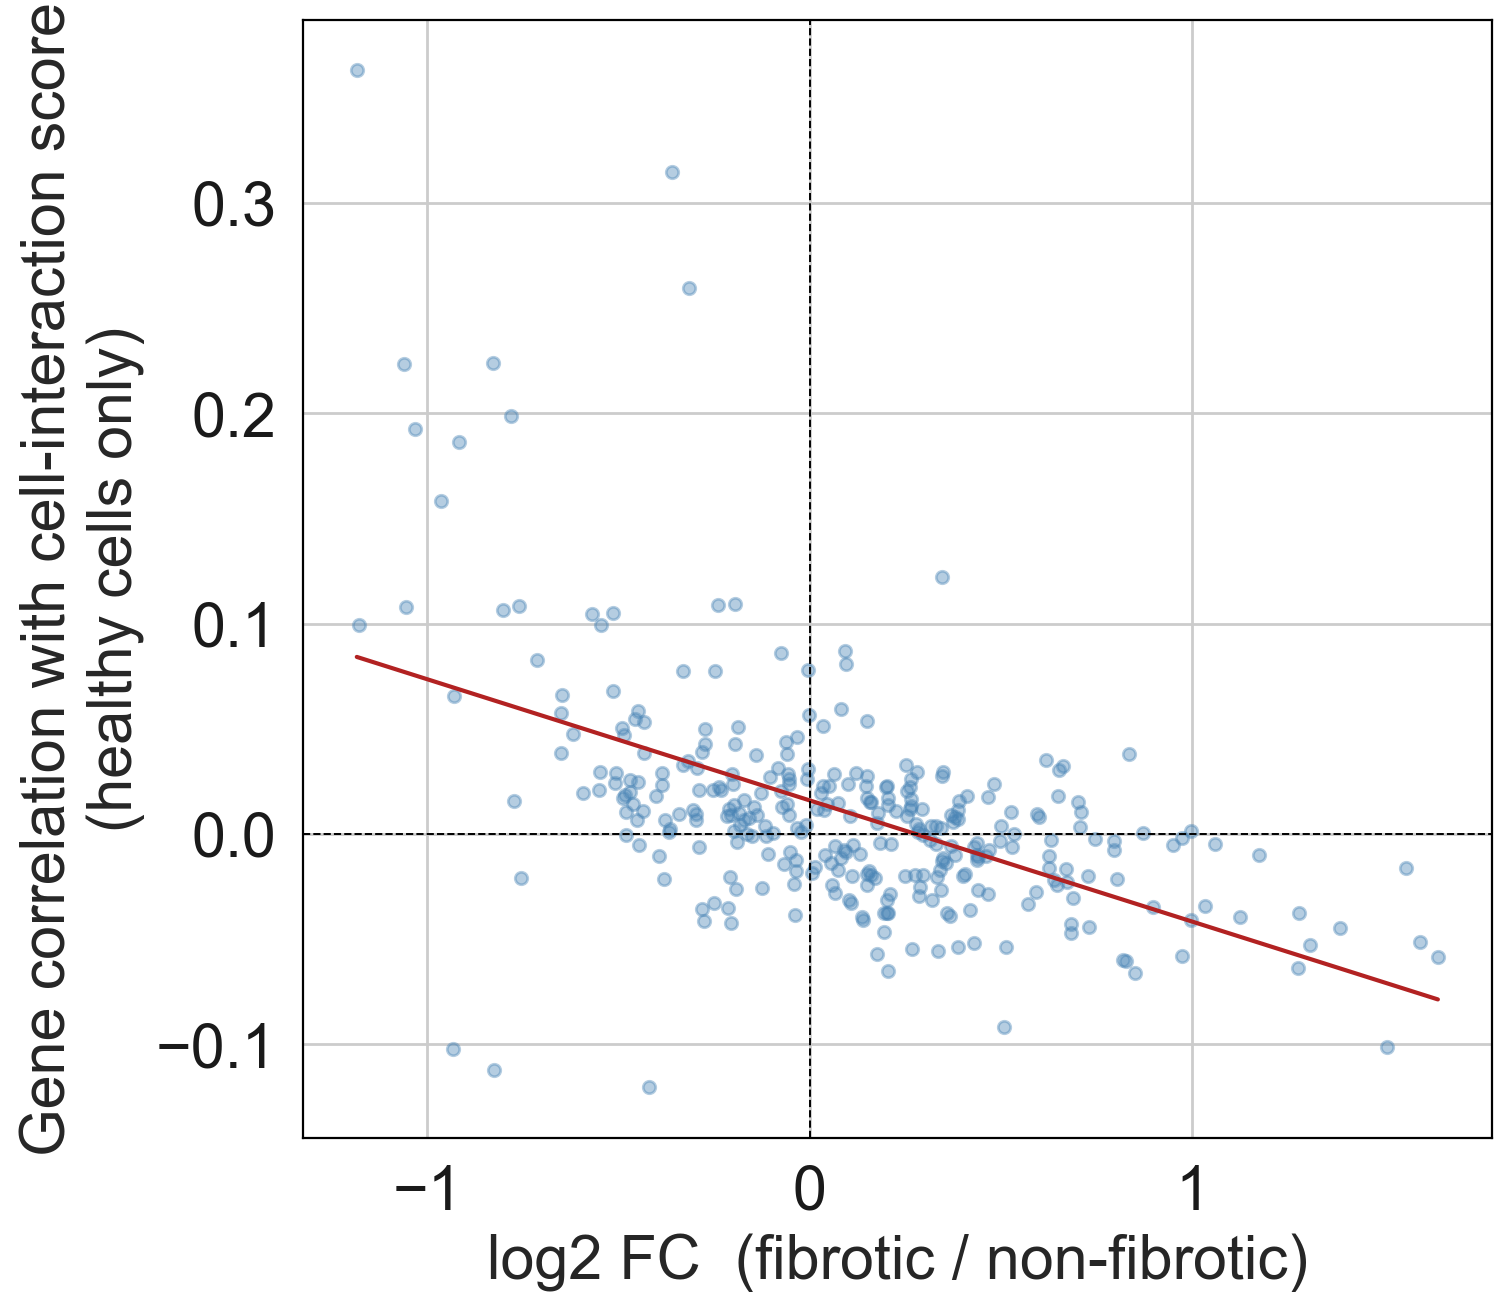


Sample AM061 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
CYP2A6        0.363077              -1.184537       0.430078
AHSG          0.223526              -1.061625       0.237301
ASGR2         0.192330              -1.032633       0.198606
SDS           0.223664              -0.828651       0.185340
FBP1          0.186229              -0.917792       0.170920
ASS1          0.198602              -0.781071       0.155122
EXT1         -0.101431               1.510961       0.153258
FGA           0.158393              -0.963826       0.152664
EPHX1         0.099343              -1.177665       0.116993
ADH1B         0.107816              -1.055274       0.113775
ALDOB         0.314941              -0.359605       0.113254
ZNF483       -0.058483               1.642907       0.096081
CYP1A2       -0.102244              -0.933352       0.095429
CYP2E1       -0.

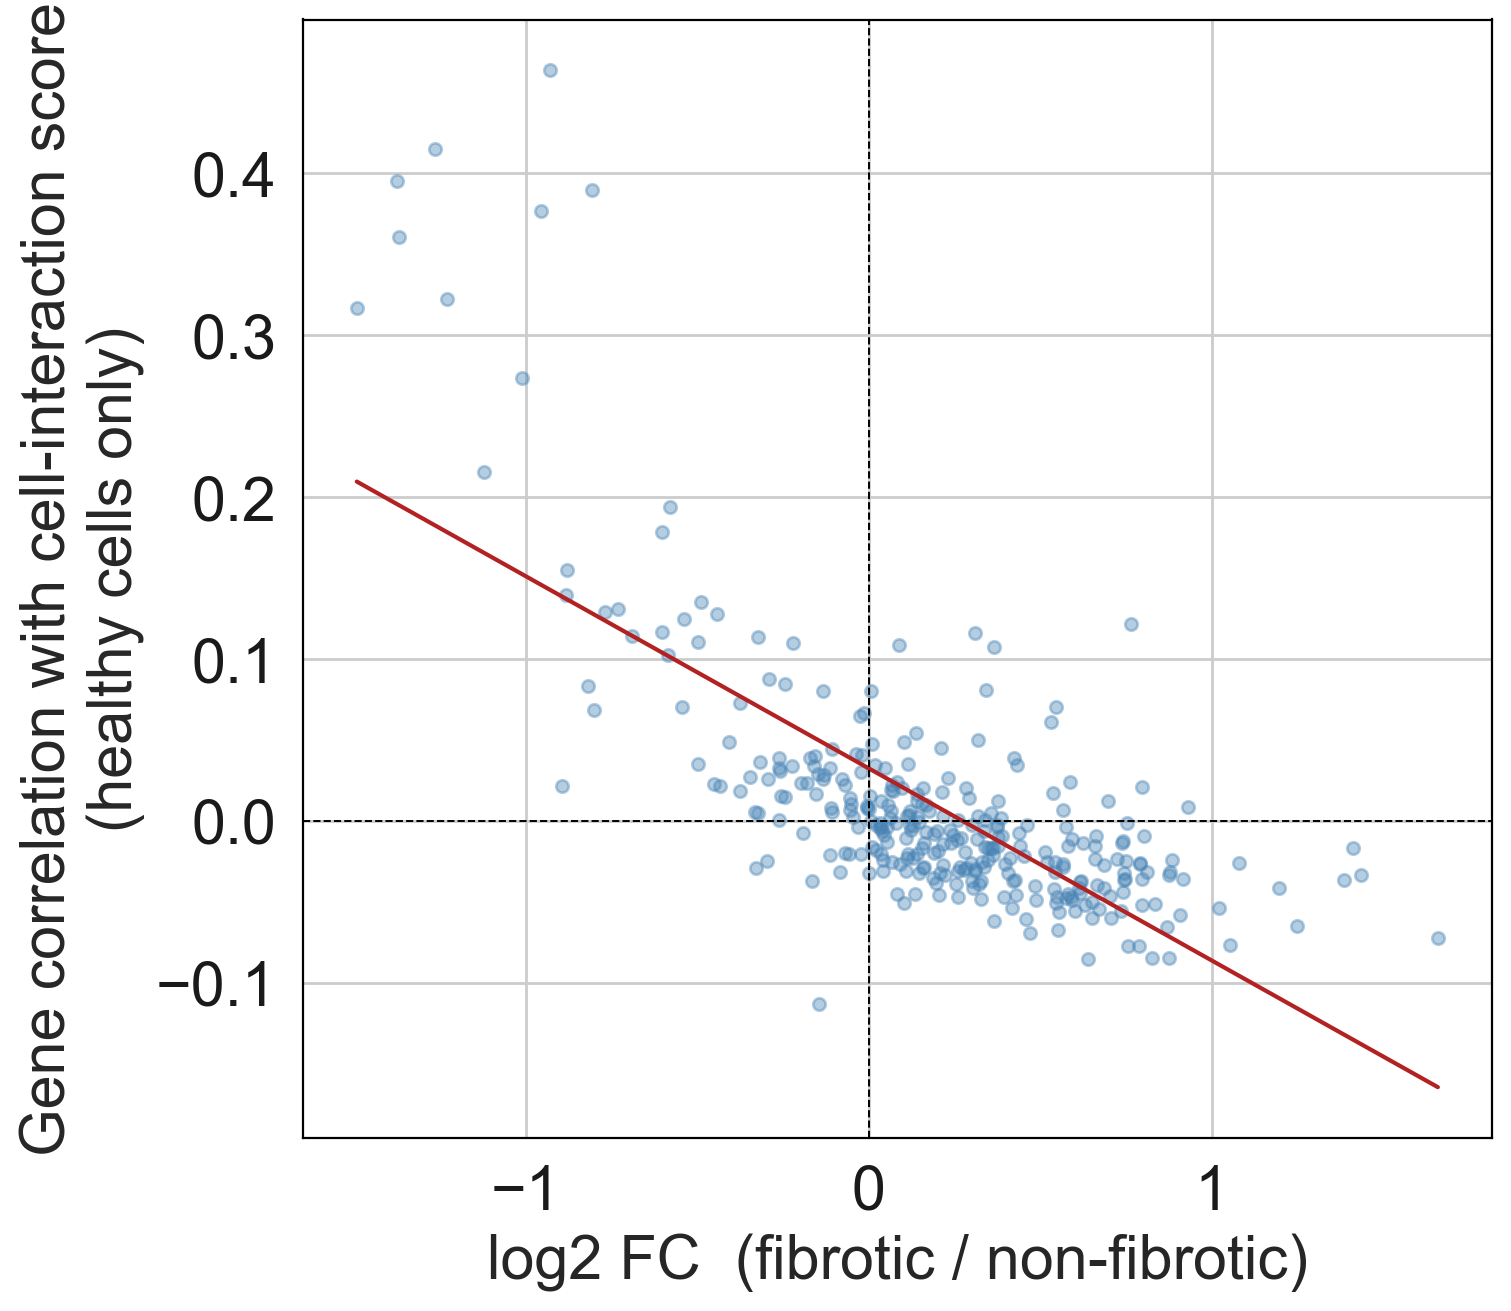


Sample AM048 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
AHSG          0.395316              -1.375592       0.543793
FGA           0.415011              -1.265419       0.525163
ADH1B         0.360932              -1.368454       0.493918
EPHX1         0.317102              -1.492773       0.473362
ALDOB         0.463700              -0.928649       0.430614
HPD           0.322613              -1.229355       0.396606
CYP2A6        0.376688              -0.956679       0.360370
SERPINA1      0.390011              -0.806292       0.314463
ASS1          0.273391              -1.010874       0.276364
ASGR2         0.215447              -1.120638       0.241438
HMGCS2        0.154877              -0.879478       0.136211
CYP2E1        0.139535              -0.883035       0.123214
MEIS2        -0.072200               1.659686       0.119830
LPA           0.

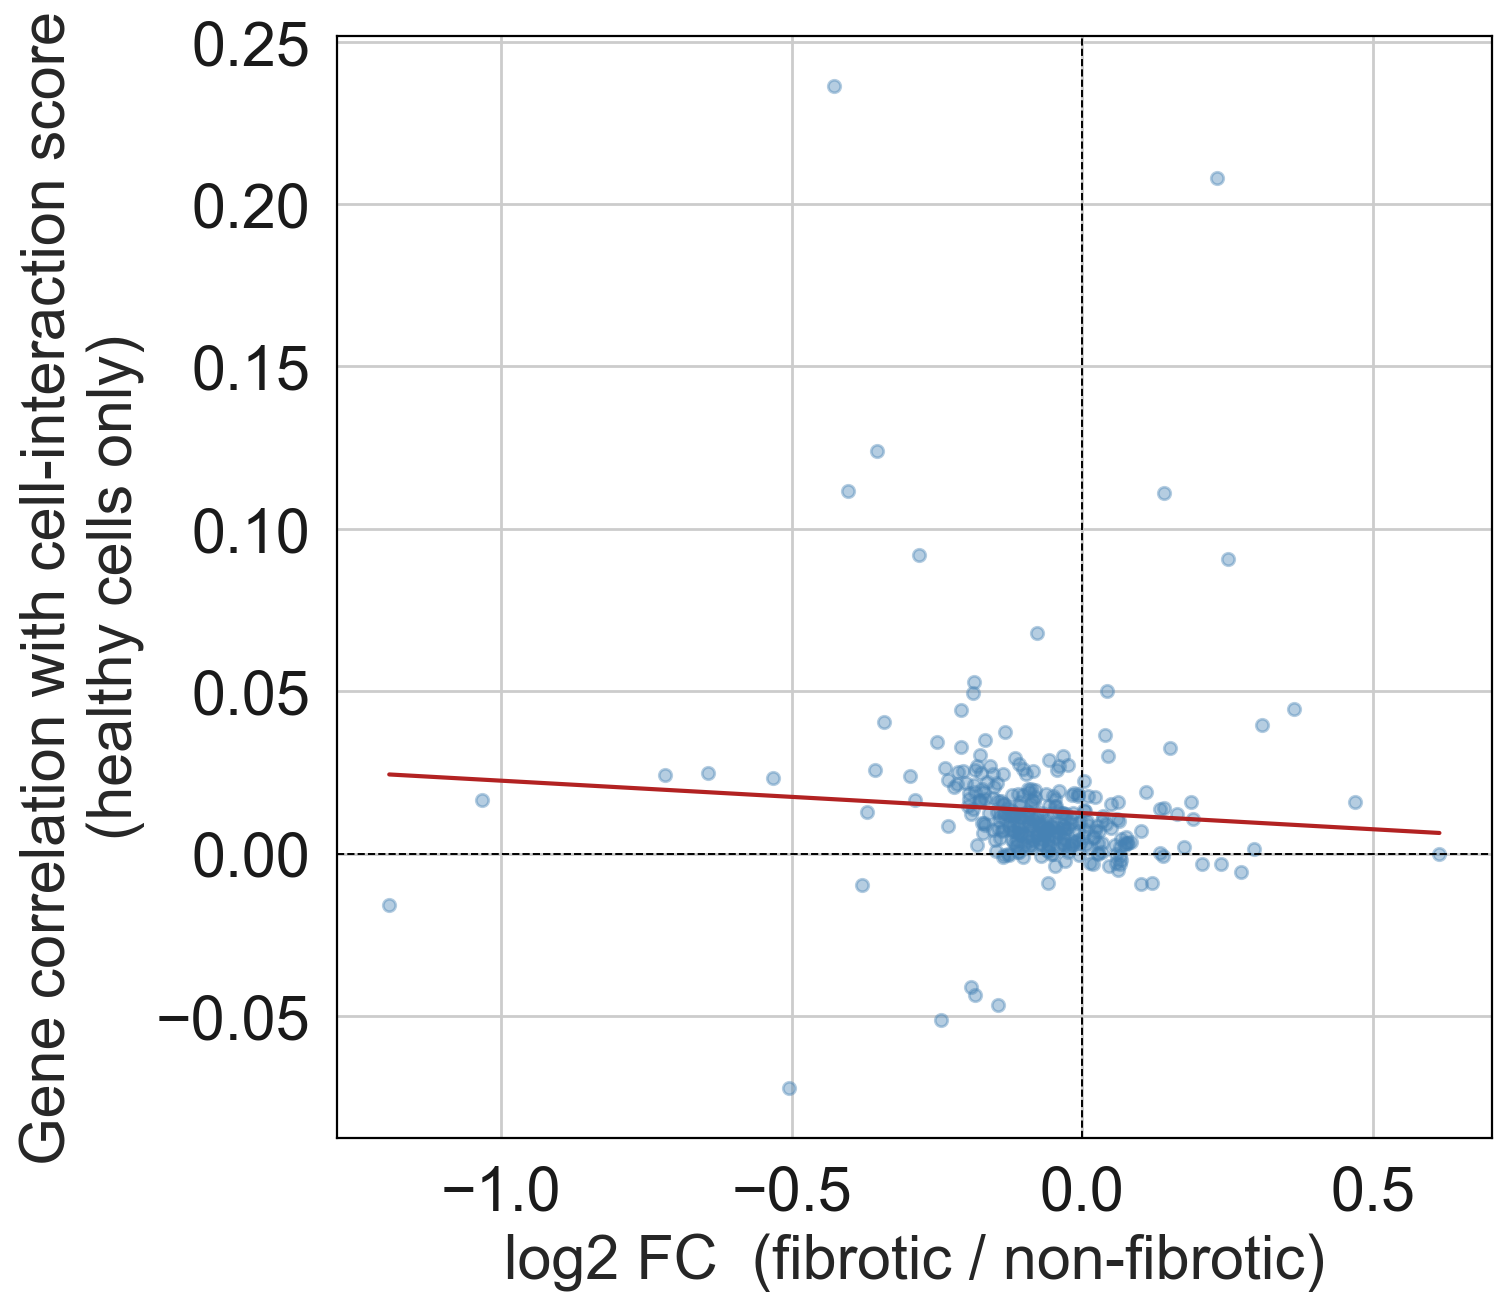


Sample AM066 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
ASS1          0.236393              -0.426297       0.100774
CPS1          0.208020               0.231354       0.048126
ALDOB         0.111761              -0.402064       0.044935
HPD           0.123843              -0.352320       0.043632
CYP2E1       -0.072128              -0.505056       0.036429
FBP1          0.092085              -0.280348       0.025816
PCK1          0.090669               0.250524       0.022715
ADH1B        -0.015670              -1.192248       0.018683
FGA           0.024296              -0.717951       0.017443
SERPINA1      0.016478              -1.032553       0.017014
SLC7A2        0.044510               0.365315       0.016260
AHSG          0.024858              -0.644119       0.016011
CYP2B6        0.110909               0.141303       0.015672
ASGR2         0.

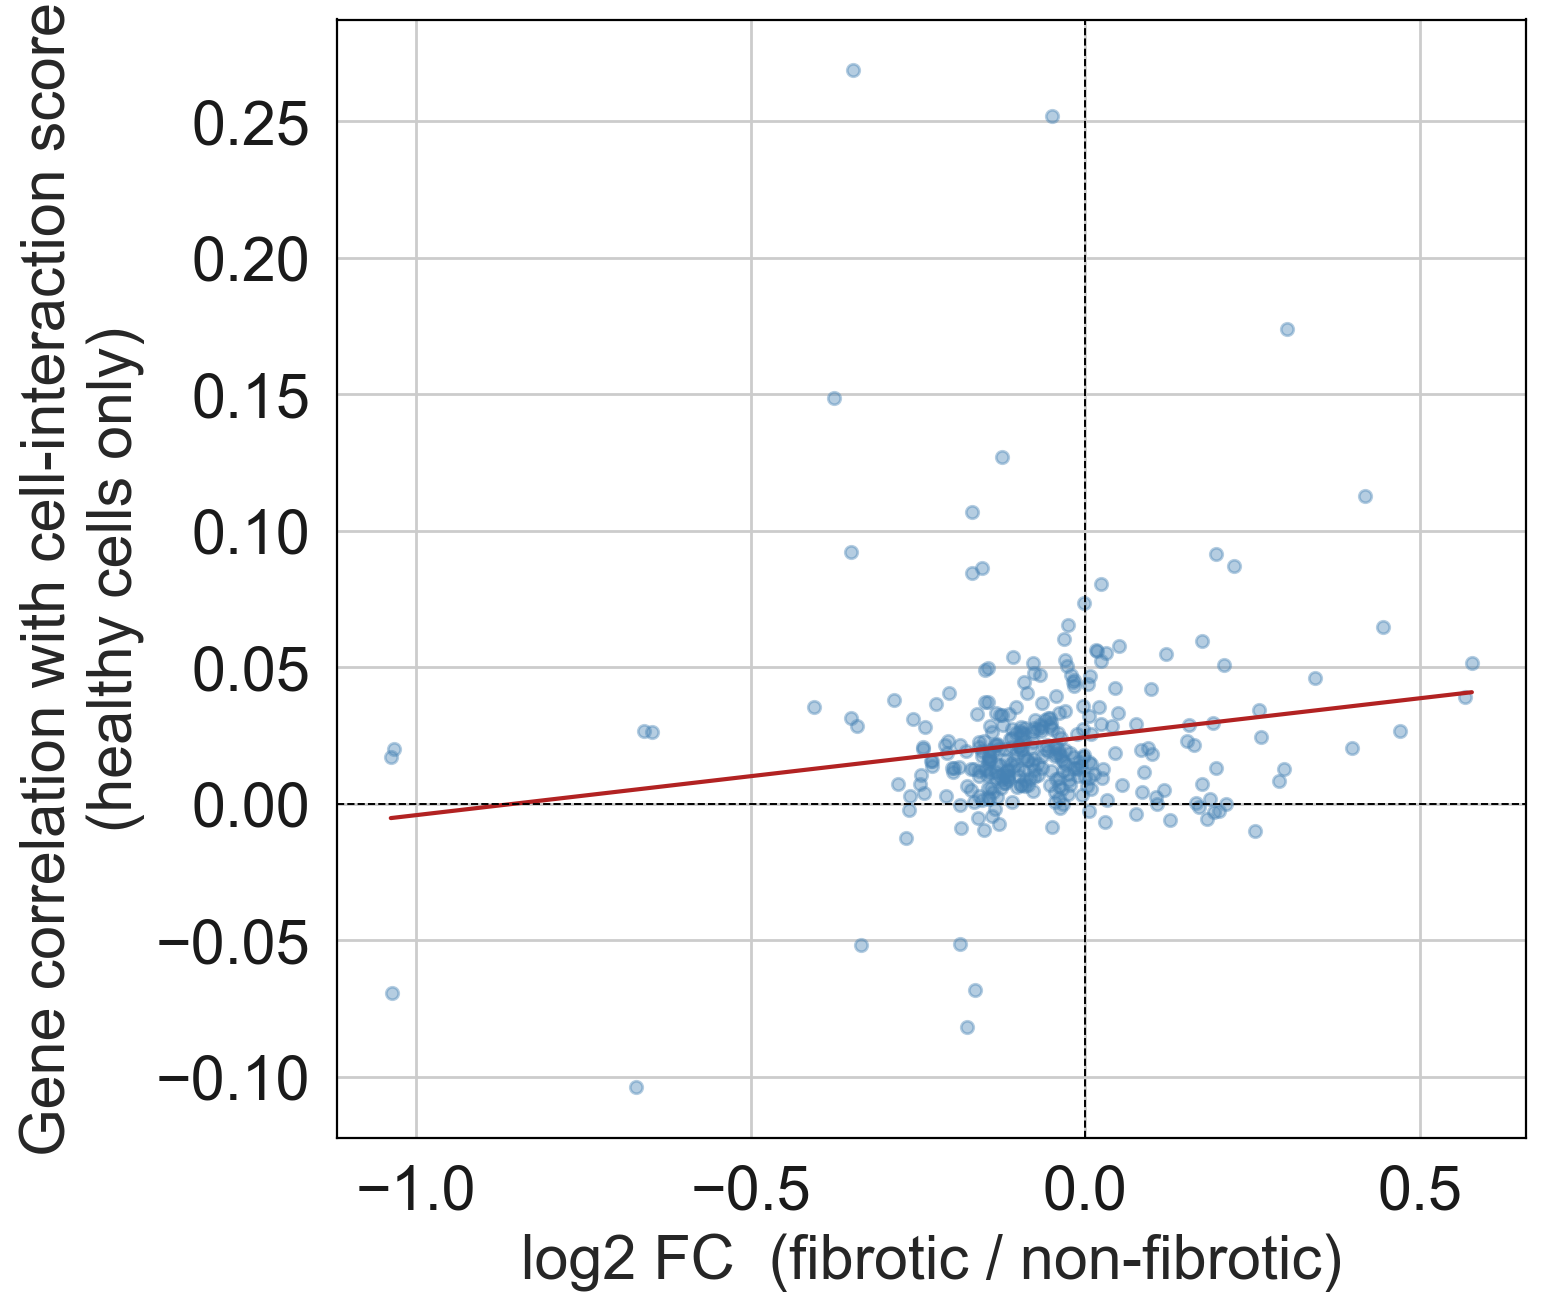


Sample AM072 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
HPD           0.268558              -0.347130       0.093224
ADH1B        -0.069194              -1.036031       0.071688
CYP2E1       -0.103851              -0.671090       0.069694
ASS1          0.148401              -0.375597       0.055739
CPS1          0.173798               0.301481       0.052397
CYP2B6        0.112716               0.418564       0.047179
ALDOB         0.092061              -0.349479       0.032173
EXT1          0.051436               0.577709       0.029715
SLC7A2        0.064803               0.444377       0.028797
ATP9A         0.038871               0.566769       0.022031
FGA           0.019863              -1.032503       0.020509
LDLR          0.086977               0.221975       0.019307
FBP1          0.106708              -0.169289       0.018065
FGFR2         0.

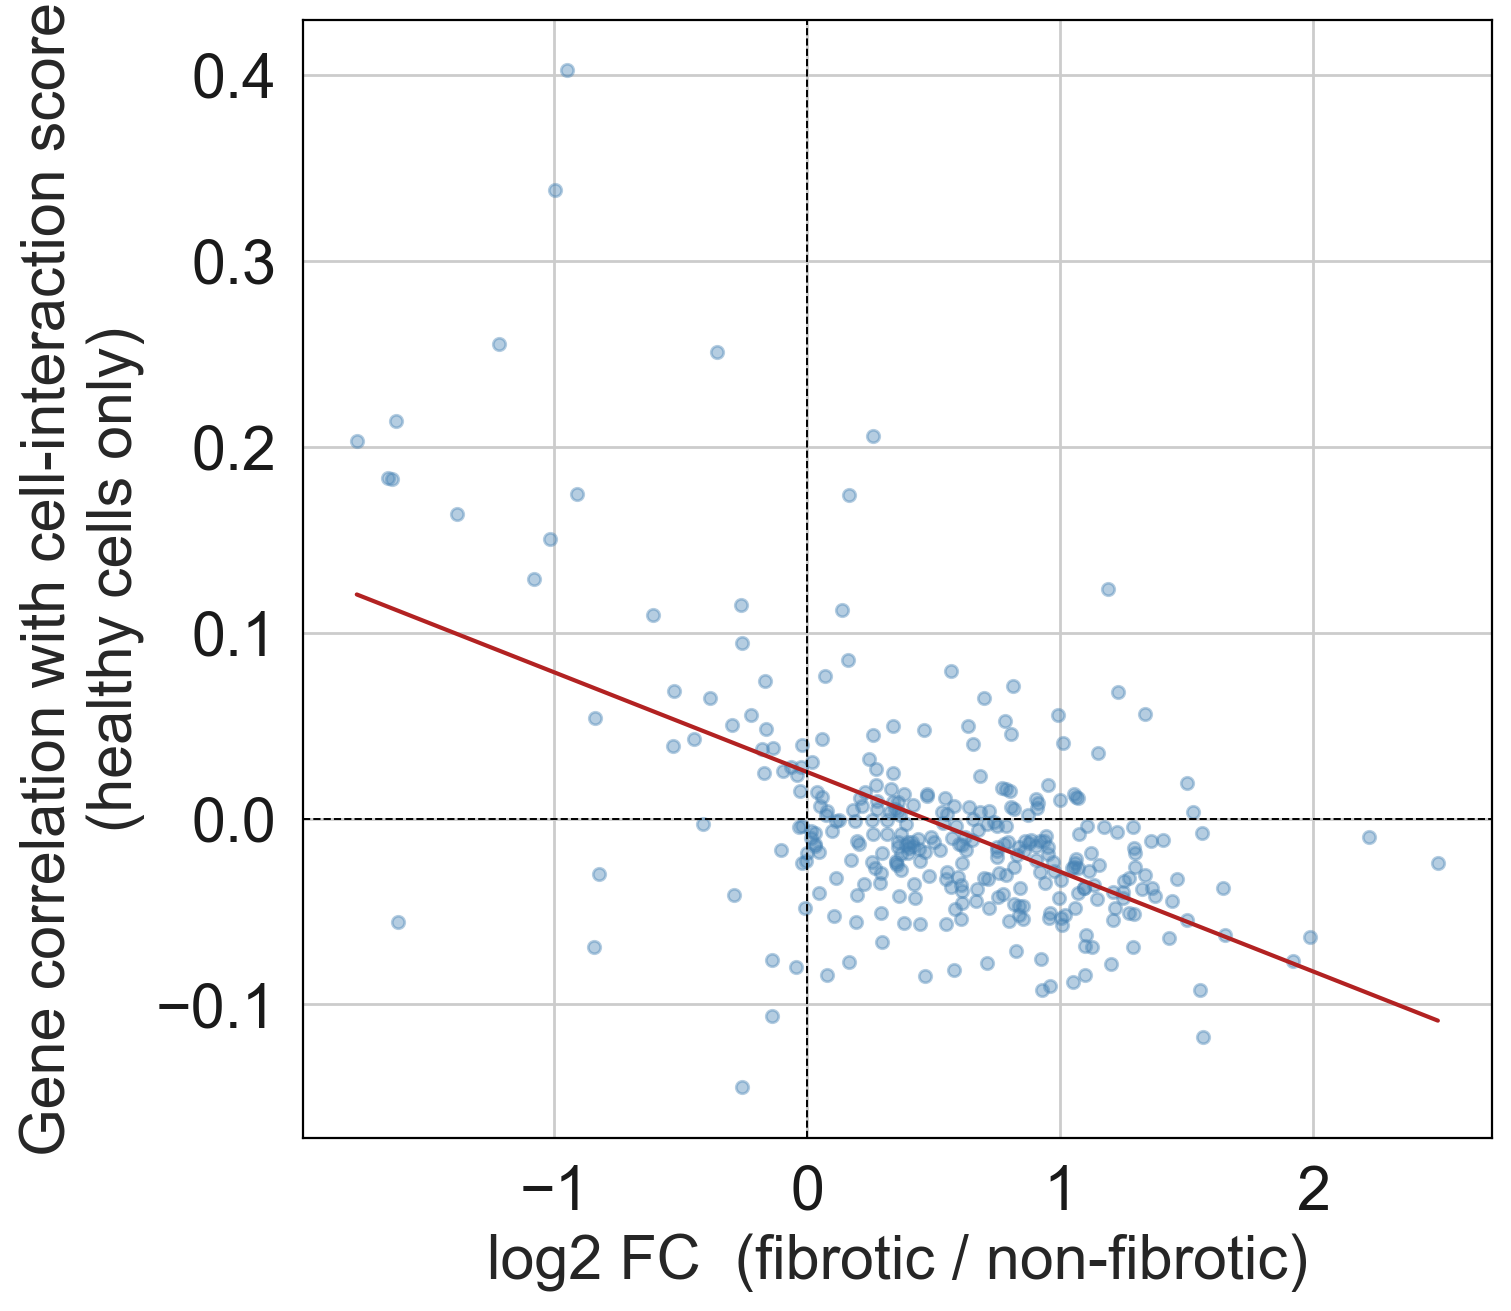


Sample AM042 — all genes ranked by anti-diagonal (DE + continuous):
            gene_score  log2fc_fibrotic_vs_nf  ranking_score
gene                                                        
ASS1          0.402382              -0.949699       0.382142
ADH1B         0.202767              -1.780298       0.360985
AHSG          0.213752              -1.624769       0.347297
ALDOB         0.337804              -0.997401       0.336926
HPD           0.255243              -1.220234       0.311456
EPHX1         0.182875              -1.658672       0.303329
FGA           0.182370              -1.641569       0.299373
SERPINA1      0.163506              -1.385618       0.226557
LDLR         -0.117580               1.564614       0.183968
LPA           0.174465              -0.911259       0.158983
TM7SF2        0.150516              -1.018008       0.153227
EXT1         -0.076503               1.917629       0.146704
ASPG          0.123601               1.186877       0.146699
CCND3        -0.

In [13]:
import importlib
import crisp.core, crisp
import liver_fibrosis_utils
importlib.reload(crisp.core)
importlib.reload(crisp)
importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_transition_genes
sc.settings.figdir = fibrosis_directory

# early_transition=True  -> high |rho|, low |FC|: genes changing before the label flips
# early_transition=False -> high |rho| x |FC|:   genes on the anti-diagonal (DE + continuous)
plot_transition_genes(cell_score="proj_pearson_cell", n_top=20, early_transition=False, only_healthy_cells=True)

In [ ]:
import importlib
import liver_fibrosis_utils
importlib.reload(liver_fibrosis_utils)
from liver_fibrosis_utils import plot_top_genes_spatial_scatter
sc.settings.figdir = fibrosis_directory

# Spatial scatter of sample 48, one plot per top-10 gene ranked by proj_pearson_gene_contrib
plot_top_genes_spatial_scatter("AM042", gene_score_key="proj_pearson_gene_contrib", n_top=1)